In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [85]:
X_train=pd.read_csv("../data/X_train.csv",usecols=[2])
X_test=pd.read_csv("../data/X_test.csv",usecols=[2])
Y_train=pd.read_csv("../data/Y_train.csv",usecols=[1])
Y_test=pd.read_csv("../data/Y_test.csv",usecols=[1])

R2 score:	 0.903587640705846
final weight:	 2.6717712039274293
final bias:	 4.0187625679675625
final MSE:	41.29400780414312
final MAE:	3.0671487512023003


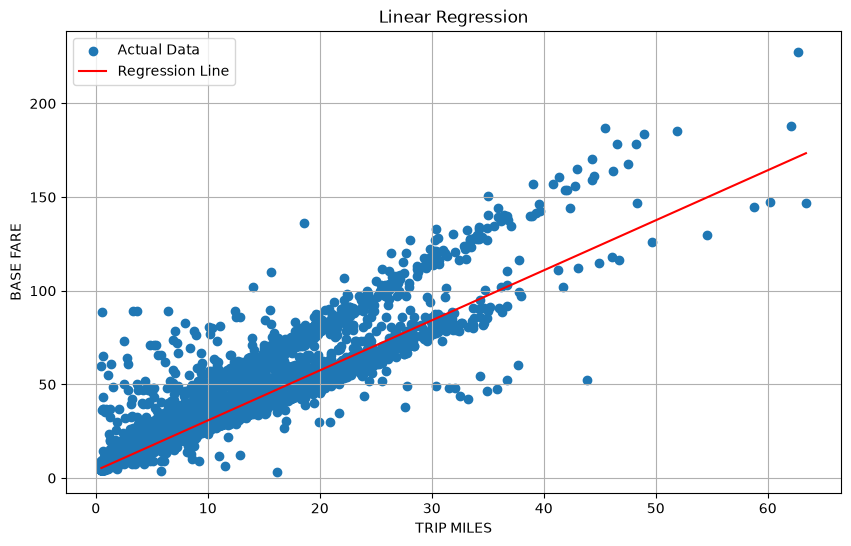

'plot_regression(\n    another_X,       # Your independent variable (X)\n    another_Y,       # Your dependent variable (Y)\n    original_w,      # Trained weight\n    b_original,      # Trained bias\n    "X_label",       # Label for the X-axis\n    "Y_label"        # Label for the Y-axis\n)'

In [118]:
    
def Linear_Regression(X_train,Y_train,X_test,Y_test,batch_size,learning_rate,epochs):
    
    
    def gradient_descent ():
        w=0
        b=0
        Y=Y_train.squeeze()
        X=X_train.squeeze()
        X_max=X.max()
        X_min=X.min()
        Y_max=Y.max()
        Y_min=Y.min()
        
        X = (X - X_min) / (X_max - X_min)
        Y= (Y- Y_min) / (Y_max- Y_min)
        for epoch in range(epochs):
            for i in range(0, len(X),batch_size):
                X_batch=X.iloc[i:i+batch_size]
                y_batch=Y.iloc[i:i+batch_size]
                y_pred=b+w*X_batch
                Actual_value_array=y_batch.to_numpy()
                predicted_value_array=y_pred.to_numpy()
                Error=(predicted_value_array-Actual_value_array)
                MSE=np.sum(Error**2)*1/len(Error)
                gradient_w=(2/len(Actual_value_array) * np.sum(Error * X_batch.to_numpy()))
                gradient_b=(2/len(Actual_value_array) * np.sum(Error))
                w-=(learning_rate*gradient_w)
                b-=(learning_rate*gradient_b)
            if not np.isfinite(w) or not np.isfinite(b):
                print("Divergence detected!")
                
                break
            prediction_AE=b+w*X
            Actual_AE=Y.to_numpy()
        
            Error_AE=(prediction_AE.to_numpy()-Actual_AE)
            MSE_AE=np.mean(Error_AE**2)
        
        
        return w,b
        gradient_descent()
    def R2_score(w1,b1):
       
        X_test_scaled=(X_test["TRIP_MILES"]-X_min)/(X_max-X_min)
        prediction_array_X_test=b1+w1*X_test_scaled.squeeze().to_numpy()
        Y_pred=Y_test.squeeze().to_numpy()
        O_pred=prediction_array_X_test*(Y_max-Y_min)+Y_min
        error=Y_pred-O_pred
        ss_res = np.sum((Y_pred - O_pred)**2)

        ss_total = np.sum((Y_pred - Y_pred.mean())**2)

        r2 = 1 - (ss_res / ss_total)
        final_MSE=np.mean(error**2)
        final_MAE=np.mean(np.abs(error))
        return r2,final_MSE,final_MAE
    w1,b1=gradient_descent()
    r2,final_MSE,final_MAE=R2_score(w1,b1)
    original_w= w1 * (Y_max - Y_min) / (X_max - X_min)
    b_original = ( Y_min+ b1 * (Y_max - Y_min)- original_w* X_min)
    
    print(f"R2 score:\t",r2)
    print(f"final weight:\t {original_w}")
    print(f"final bias:\t {b_original}")
    print(f"final MSE:\t{final_MSE}")
    print(f"final MAE:\t{final_MAE}")
    return r2,original_w,b_original,final_MSE,final_MAE

    
    
    
            




def plot_regression(X, Y, original_w, b_original,
                    x_label="X", y_label="Y"):

    
    X = X_train.squeeze().to_numpy()
    Y = Y_train.squeeze().to_numpy()
    X_line = np.linspace(X.min(), X.max(), 100)
    Y_line = original_w * X_line + b_original
    plt.figure(figsize=(10, 6))
    plt.scatter(X, Y, label="Actual Data")
    plt.plot(X_line, Y_line, color="red", label="Regression Line")
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title("Linear Regression")
    plt.legend()
    plt.grid(True)
    plt.show()

## NOTE:
## This code performs Linear Regression on the
## "chicago_taxi_train.csv" dataset.
## The code may need to be modified when working
## with a different dataset, depending on its features,
## target column, and preprocessing requirements.
r2, original_w, b_original, final_MSE, final_MAE = Linear_Regression(
    X_train, Y_train, X_test, Y_test, 100, 0.03, 50
)

plot_regression(
    X_train["TRIP_MILES"],
    Y_train["BASE FARE"],
    original_w,
    b_original,
    "TRIP MILES",
    "BASE FARE"
)
## To use this function with another dataset, replace the code
## from line 102, column 1 to line 109, column 2
## with the following template.
## Modify the arguments according to your dataset:

# plot_regression(
#     another_X,       # Your independent variable (X)
#     another_Y,       # Your dependent variable (Y)
#     original_w,      # Trained weight
#     b_original,      # Trained bias
#     "X_label",       # Label for the X-axis
#     "Y_label"        # Label for the Y-axis
# )
